# JW $Z_4^{TF}$ system - cocycle extraction - larger system - analyse results

Created: 14-10-2026

Objectives:
* Analyze results from [this notebook](jw_z_4_tf_system_cocycle_extraction_larger_system_analyse_results.ipynb).

# Imports

In [1]:
import numpy as np

In [2]:
import jax
jax.config.update('jax_platform_name', 'cpu')

import jax.numpy as jnp

In [3]:
import matplotlib.pyplot as plt

In [4]:
from tqdm import tqdm

In [5]:
from functools import reduce
from operator import mul
from itertools import product

In [6]:
from random import random

In [7]:
import quimb.tensor as qtn
import quimb as qu

In [8]:
from scipy.stats import unitary_group

In [9]:
from collections import Counter

In [10]:
import pandas as pd

In [11]:
from time import time

In [12]:
from humanize import naturalsize

In [13]:
import pickle

# Cluster state - results

In [14]:
with open(r"results/z_4_tf_cluster_results.pkl", "rb") as file:
    results = pickle.load(file)

### Analyze results

#### Projector scores

In [15]:
np.round(np.array([
    d['left_proj_vec_results'][0][-1]
    for d in results
]), 3)

array([-0.,  0., -0., -0.,  0., -0., -0., -0.,  0., -0., -0., -0., -0.,
       -0.,  0., -0.,  0., -0., -0.,  0., -0.,  0.,  0.,  0., -0.,  0.,
       -0., -0.,  0., -0., -0.,  0., -0.,  0., -0.,  0.,  0., -0., -0.,
        0., -0.,  0.,  0.,  0.,  0., -0.,  0.,  0., -0.,  0.,  0., -0.,
       -0.,  0.,  0.,  0., -0.,  0., -0., -0., -0., -0., -0., -0.,  0.,
        0., -0.,  0.,  0.,  0., -0.,  0.,  0., -0., -0.,  0.,  0.,  0.,
       -0.,  0., -0.,  0.,  0.,  0.,  0., -0., -0., -0.,  0.,  0.,  0.,
        0.,  0., -0.,  0., -0.,  0., -0.,  0.,  0., -0.,  0., -0.,  0.,
        0.,  0.,  0., -0.,  0., -0., -0.,  0.,  0.,  0., -0., -0., -0.,
        0., -0., -0.,  0., -0.,  0.,  0., -0.,  0.,  0., -0.,  0.,  0.,
        0.,  0.,  0., -0., -0., -0., -0., -0.,  0.,  0., -0.,  0., -0.,
        0.,  0.,  0., -0.,  0., -0.,  0., -0., -0.,  0.,  0.,  0.,  0.,
        0.,  0.,  0.,  0.,  0.,  0.,  0., -0., -0.,  0.,  0., -0., -0.,
        0., -0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0

In [16]:
np.round(np.array([
    d['right_proj_vec_results'][0][-1]
    for d in results
]), 3)

array([-0., -0.,  0., -0.,  0., -0.,  0.,  0.,  0.,  0.,  0.,  0., -0.,
        0.,  0., -0.,  0.,  0., -0., -0., -0., -0.,  0., -0.,  0.,  0.,
       -0.,  0.,  0., -0.,  0.,  0.,  0.,  0.,  0., -0.,  0.,  0.,  0.,
        0., -0., -0., -0., -0.,  0., -0.,  0., -0., -0.,  0.,  0.,  0.,
        0.,  0.,  0.,  0.,  0.,  0.,  0., -0.,  0.,  0.,  0.,  0.,  0.,
        0.,  0., -0.,  0.,  0.,  0.,  0.,  0.,  0., -0.,  0., -0., -0.,
       -0.,  0.,  0.,  0.,  0.,  0., -0., -0., -0.,  0., -0.,  0.,  0.,
        0., -0.,  0.,  0.,  0., -0., -0., -0.,  0.,  0.,  0., -0.,  0.,
       -0.,  0., -0., -0.,  0.,  0.,  0., -0., -0.,  0.,  0.,  0.,  0.,
       -0.,  0.,  0.,  0., -0.,  0.,  0.,  0.,  0.,  0.,  0.,  0., -0.,
        0.,  0.,  0.,  0., -0., -0.,  0.,  0.,  0.,  0., -0.,  0., -0.,
        0.,  0.,  0., -0., -0.,  0.,  0.,  0.,  0., -0.,  0.,  0.,  0.,
        0., -0., -0., -0.,  0.,  0., -0., -0.,  0.,  0., -0.,  0.,  0.,
        0.,  0.,  0.,  0., -0.,  0.,  0., -0., -0.,  0.,  0.,  0

There is an error interpreting these, according to ChatGPT.

In [17]:
def get_schmidt_vals_ratio(schmidt_vals):
    if len(schmidt_vals.data) > 1:
        return schmidt_vals.data[1]/schmidt_vals.data[0]
    else:
        return 0

In [18]:
np.round(np.array([
    get_schmidt_vals_ratio(d['left_proj_vec_results'][1])
    for d in results
]), 3)

array([0.285, 0.103, 0.062, 0.059, 0.057, 0.603, 0.638, 0.003, 0.065,
       0.059, 0.264, 0.003, 0.106, 0.432, 0.314, 0.684, 0.625, 0.247,
       0.061, 0.304, 0.019, 0.333, 0.15 , 0.268, 0.203, 0.263, 0.11 ,
       0.396, 0.009, 0.249, 0.519, 0.098, 0.038, 0.49 , 0.093, 0.125,
       0.039, 0.054, 0.033, 0.533, 0.731, 0.207, 0.289, 0.127, 0.062,
       0.611, 0.547, 0.068, 0.603, 0.06 , 0.488, 0.   , 0.17 , 0.086,
       0.262, 0.042, 0.232, 0.113, 0.752, 0.114, 0.046, 0.016, 0.476,
       0.495, 0.068, 0.572, 0.685, 0.114, 0.095, 0.034, 0.039, 0.688,
       0.099, 0.008, 0.246, 0.504, 0.125, 0.048, 0.175, 0.623, 0.286,
       0.459, 0.315, 0.021, 0.064, 0.001, 0.261, 0.557, 0.02 , 0.068,
       0.217, 0.183, 0.082, 0.6  , 0.871, 0.146, 0.404, 0.245, 0.069,
       0.933, 0.274, 0.12 , 0.005, 0.265, 0.033, 0.047, 0.092, 0.008,
       0.557, 0.604, 0.188, 0.066, 0.135, 0.133, 0.072, 0.156, 0.541,
       0.17 , 0.071, 0.304, 0.294, 0.387, 0.128, 0.293, 0.117, 0.374,
       0.467, 0.184,

In [19]:
np.round(np.array([
    get_schmidt_vals_ratio(d['right_proj_vec_results'][1])
    for d in results
]), 3)

array([0.116, 0.534, 0.146, 0.442, 0.274, 0.276, 0.375, 0.342, 0.282,
       0.252, 0.501, 0.592, 0.376, 0.164, 0.699, 0.228, 0.226, 0.271,
       0.372, 0.791, 0.21 , 0.324, 0.948, 0.457, 0.036, 0.358, 0.373,
       0.661, 0.119, 0.367, 0.161, 0.068, 0.065, 0.839, 0.225, 0.19 ,
       0.32 , 0.429, 0.414, 0.395, 0.15 , 0.346, 0.163, 0.437, 0.492,
       0.23 , 0.27 , 0.613, 0.569, 0.182, 0.44 , 0.28 , 0.696, 0.242,
       0.532, 0.104, 0.274, 0.354, 0.247, 0.528, 0.118, 0.124, 0.203,
       0.725, 0.919, 0.204, 0.522, 0.492, 0.347, 0.399, 0.149, 0.486,
       0.45 , 0.121, 0.085, 0.396, 0.076, 0.22 , 0.37 , 0.213, 0.108,
       0.191, 0.262, 0.196, 0.199, 0.119, 0.072, 0.1  , 0.233, 0.513,
       0.338, 0.436, 0.604, 0.329, 0.092, 0.533, 0.357, 0.609, 0.585,
       0.07 , 0.383, 0.359, 0.101, 0.547, 0.579, 0.167, 0.076, 0.46 ,
       0.064, 0.099, 0.012, 0.396, 0.378, 0.763, 0.115, 0.07 , 0.257,
       0.305, 0.587, 0.232, 0.154, 0.485, 0.276, 0.355, 0.15 , 0.086,
       0.484, 0.203,

#### Purities

In [20]:
np.round(np.array(
    [d['cut_rho_purity'] for d in results]
), 3)

array([1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j, 0.999-0.j, 0.999+0.j,
       1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 0.999+0.j, 1.   -0.j,
       1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 0.999-0.j, 1.   +0.j,
       1.   -0.j, 1.   -0.j, 1.   +0.j, 0.999+0.j, 1.   +0.j, 1.   -0.j,
       1.   +0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j,
       1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j, 0.999-0.j,
       1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j,
       1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   -0.j,
       1.   -0.j, 0.997-0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j,
       1.   -0.j, 1.   -0.j, 1.   -0.j, 0.998+0.j, 1.   -0.j, 1.   +0.j,
       0.999+0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j,
       1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j,
       1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   -0.j,
       1.   +0.j, 0.999-0.j, 1.   -0.j, 1.   +0.j, 

In [21]:
np.round(np.array(
    [d['sub_cut_rho_trace'] for d in results]
), 3)

array([1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j,
       1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j,
       1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j,
       1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j,
       1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j,
       1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j,
       1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j,
       1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j,
       1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j,
       1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j,
       1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j,
       1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j,
       1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j,
       1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j,
      

In [22]:
np.round(np.array(
    [d['sub_cut_rho_purity'] for d in results]
), 3)

array([1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j, 0.999-0.j, 0.999+0.j,
       1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 0.999+0.j, 1.   -0.j,
       1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 0.999-0.j, 1.   +0.j,
       1.   -0.j, 1.   -0.j, 1.   +0.j, 0.999+0.j, 1.   +0.j, 1.   -0.j,
       1.   +0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j,
       1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j, 0.999-0.j,
       1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j,
       1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   -0.j,
       1.   -0.j, 0.997-0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j,
       1.   -0.j, 1.   -0.j, 1.   -0.j, 0.998+0.j, 1.   -0.j, 1.   +0.j,
       0.999+0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j,
       1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j,
       1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   -0.j,
       1.   +0.j, 0.999-0.j, 1.   -0.j, 1.   +0.j, 

Purities are the same, which one could likely prove.

In [23]:
np.round(np.array(
    [d['sub_cut_rho_purity'] for d in results]
), 3)

array([1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j, 0.999-0.j, 0.999+0.j,
       1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 0.999+0.j, 1.   -0.j,
       1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 0.999-0.j, 1.   +0.j,
       1.   -0.j, 1.   -0.j, 1.   +0.j, 0.999+0.j, 1.   +0.j, 1.   -0.j,
       1.   +0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j,
       1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   -0.j, 0.999-0.j,
       1.   +0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   -0.j, 1.   +0.j,
       1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   -0.j,
       1.   -0.j, 0.997-0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j,
       1.   -0.j, 1.   -0.j, 1.   -0.j, 0.998+0.j, 1.   -0.j, 1.   +0.j,
       0.999+0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j,
       1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   -0.j, 1.   +0.j,
       1.   +0.j, 1.   -0.j, 1.   +0.j, 1.   +0.j, 1.   +0.j, 1.   -0.j,
       1.   +0.j, 0.999-0.j, 1.   -0.j, 1.   +0.j, 

In [24]:
X = np.array(
    [d['sub_cut_rho_purity'] for d in results]
)

In [25]:
np.max(np.abs(np.imag(X)))

np.float64(6.366435156834882e-16)

In [26]:
X = np.real(X)

In [27]:
pd.Series(X).describe()

count    1000.000000
mean        0.999780
std         0.000791
min         0.988749
25%         0.999932
50%         0.999989
75%         0.999998
max         1.000000
dtype: float64

(array([  1.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   1.,   0.,   0.,   0.,   1.,   0.,   0.,   0.,
          0.,   0.,   1.,   0.,   0.,   1.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   1.,   0.,   0.,   1.,   0.,   0.,   1.,   2.,
          0.,   1.,   0.,   0.,   0.,   2.,   1.,   0.,   2.,   0.,   3.,
          1.,   2.,   2.,   4.,   0.,   3.,   1.,   2.,   2.,   4.,   5.,
          7.,   3.,   3.,   7.,   7.,   8.,  11.,  13.,  19.,  18.,  47.,
        812.]),
 array([0.98874861, 0.98886113, 0.98897364, 0.98908615, 0.98919867,
        0.98931118, 0.98942369, 0.98953621, 0.98964872, 0.98976124,
        0.98987375, 0.98998626, 0.99009878, 0.99021129, 0.9903238 ,
        0.99043632, 0.99054883, 0.99066134, 0.99077386, 0.99088637,
        0.99099889, 0.9911114 , 0.99122391, 0.

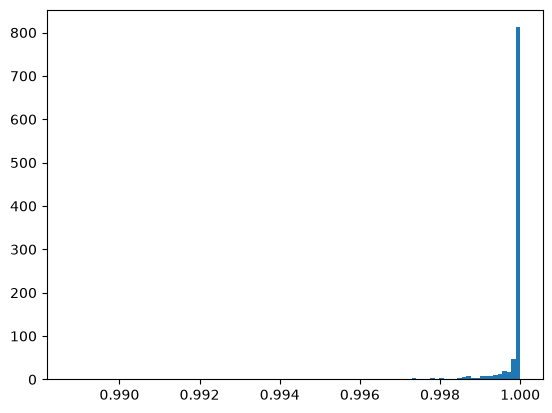

In [28]:
plt.hist(X, bins=100)

#### Cut state results

In [29]:
np.array(
    [d['cut_state_fermion_parity'] for d in results]
)

array([-1.+5.75519038e-20j, -1.+9.85441574e-19j, -1.-1.29332586e-18j,
        1.-1.53332542e-18j, -1.-9.91975948e-19j,  1.+9.38465278e-19j,
       -1.-5.77921147e-19j,  1.+1.99990559e-18j, -1.+3.42295308e-20j,
        1.+4.27106195e-19j, -1.+2.44166406e-18j,  1.-1.41779133e-19j,
        1.+7.99597245e-19j, -1.-5.26011286e-19j,  1.+9.10481056e-19j,
        1.-1.18353665e-19j, -1.+1.03045152e-18j,  1.+1.18477273e-18j,
       -1.-1.34239666e-18j,  1.+6.57170816e-19j, -1.+2.13766735e-18j,
       -1.+1.82103200e-18j, -1.-2.03735967e-18j,  1.-2.48896824e-19j,
        1.-1.73041537e-18j,  1.-1.50030841e-19j, -1.-1.40205612e-18j,
        1.-4.81787621e-19j,  1.+3.66044086e-19j,  1.-2.05683425e-18j,
       -1.-4.93376030e-19j,  1.-4.01403810e-19j,  1.-1.08325778e-18j,
       -1.-1.00488681e-18j,  1.-3.83074600e-19j, -1.+8.95373163e-19j,
        1.-1.03332725e-19j, -1.-2.45345851e-19j, -1.+7.75557861e-20j,
       -1.+5.55880373e-19j,  1.+4.17854606e-20j,  1.+1.22597728e-18j,
       -1.+1.1240154

In [30]:
np.round(np.array(
    [d['cut_overlap'] for d in results]
), 3)

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1.

#### Defect op scores overlaps

In [31]:
np.round(np.array([
    [d['defect_ops_scores'][i][-1] for d in results]
    for i in range(3)
]), 5)

array([[0.99977, 0.99952, 0.99914, ..., 0.99998, 1.     , 0.99997],
       [1.     , 1.     , 1.     , ..., 1.     , 1.     , 1.     ],
       [0.99977, 0.99952, 0.99914, ..., 0.99998, 1.     , 0.99997]],
      shape=(3, 1000))

In [32]:
X = np.array([
    [d['defect_ops_scores'][i][-1] for d in results]
    for i in range(3)
])

In [33]:
pd.DataFrame(X.T).describe()

,0,1,2
count,1000.000000,1.000000e+03,1000.000000
mean,0.970708,1.000000e+00,0.970708
std,0.070107,2.722654e-16,0.070107
min,0.379531,1.000000e+00,0.379531
25%,0.984792,1.000000e+00,0.984792
50%,0.997895,1.000000e+00,0.997895
75%,0.999804,1.000000e+00,0.999804
max,1.000000,1.000000e+00,1.000000


(array([  1.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   1.,   0.,   0.,   1.,   0.,   1.,
          0.,   0.,   0.,   0.,   0.,   1.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   1.,   0.,
          1.,   2.,   1.,   3.,   3.,   0.,   2.,   0.,   0.,   0.,   0.,
          1.,   3.,   3.,   3.,   1.,   0.,   5.,   1.,   0.,   2.,   3.,
          1.,   2.,   1.,   3.,   2.,   0.,   4.,   1.,   6.,   3.,   4.,
          6.,   7.,   6.,   3.,   5.,   6.,   0.,   6.,   8.,   7.,   2.,
          8.,   1.,   6.,   8.,  13.,  13.,  13.,  21.,  31.,  40.,  89.,
        634.]),
 array([0.37953075, 0.38573544, 0.39194014, 0.39814483, 0.40434952,
        0.41055421, 0.41675891, 0.4229636 , 0.42916829, 0.43537298,
        0.44157768, 0.44778237, 0.45398706, 0.46019175, 0.46639645,
        0.47260114, 0.47880583, 0.48501052, 0.49121522, 0.49741991,
        0.5036246 , 0.50982929, 0.51603399, 0.

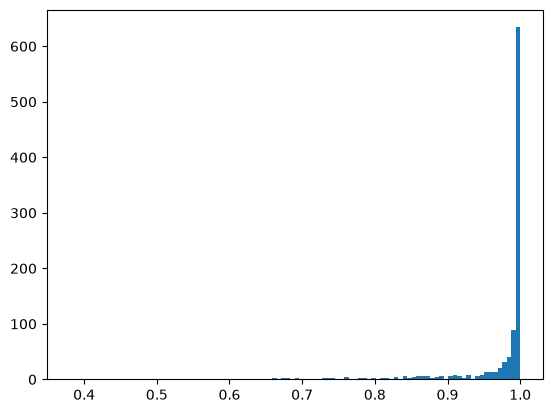

In [34]:
plt.hist(X[0], bins=100)

#### Phases

In [35]:
left_phases = np.array([
    d['left_defect_op_invariant'] for d in results
])

In [36]:
left_phases.shape

(1000,)

In [37]:
np.max(np.abs(np.imag(left_phases)))

np.float64(2.6818227780373623e-16)

In [38]:
left_phases = np.real(left_phases)

In [39]:
pd.Series(left_phases).describe()

count    1000.000000
mean       -0.999980
std         0.000082
min        -1.000000
25%        -1.000000
50%        -1.000000
75%        -0.999998
max        -0.998878
dtype: float64

(array([852.,  39.,  17.,  13.,  12.,  11.,   2.,   2.,   2.,   1.,   2.,
          2.,   2.,   5.,   2.,   2.,   2.,   1.,   3.,   2.,   3.,   1.,
          0.,   1.,   1.,   2.,   2.,   1.,   2.,   0.,   0.,   1.,   0.,
          0.,   0.,   0.,   0.,   1.,   0.,   0.,   0.,   0.,   1.,   0.,
          0.,   1.,   0.,   2.,   1.,   1.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   1.,   0.,   0.,   1.,   1.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   1.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          1.]),
 array([-1.        , -0.99998878, -0.99997757, -0.99996635, -0.99995513,
        -0.99994392, -0.9999327 , -0.99992149, -0.99991027, -0.99989905,
        -0.99988784, -0.99987662, -0.9998654 , -0.99985419, -0.99984297,
        -0.99983176, -0.99982054, -0.99980932, -0.99979811, -0.99978689,
        -0.99977567, -0.99

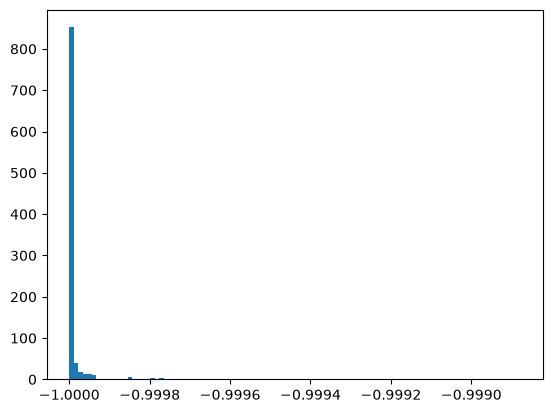

In [40]:
plt.hist(left_phases, bins=100)

In [41]:
right_phases = np.array([
    d['right_defect_op_invariant'] for d in results
])

In [42]:
right_phases.shape

(1000,)

In [43]:
np.max(np.abs(np.imag(right_phases)))

np.float64(2.540768895960166e-16)

In [44]:
right_phases = np.real(right_phases)

In [45]:
pd.Series(right_phases).describe()

count    1000.000000
mean       -0.999970
std         0.000144
min        -1.000000
25%        -1.000000
50%        -0.999999
75%        -0.999996
max        -0.997694
dtype: float64

(array([886.,  34.,  13.,   9.,   5.,   4.,   3.,   1.,   4.,   3.,   5.,
          2.,   3.,   0.,   1.,   2.,   1.,   5.,   2.,   0.,   2.,   1.,
          1.,   0.,   0.,   0.,   2.,   0.,   1.,   0.,   0.,   1.,   1.,
          0.,   0.,   2.,   0.,   0.,   0.,   0.,   1.,   0.,   0.,   0.,
          0.,   0.,   0.,   2.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   1.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   1.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          1.]),
 array([-1.        , -0.99997694, -0.99995388, -0.99993083, -0.99990777,
        -0.99988471, -0.99986165, -0.9998386 , -0.99981554, -0.99979248,
        -0.99976942, -0.99974636, -0.99972331, -0.99970025, -0.99967719,
        -0.99965413, -0.99963108, -0.99960802, -0.99958496, -0.9995619 ,
        -0.99953885, -0.99

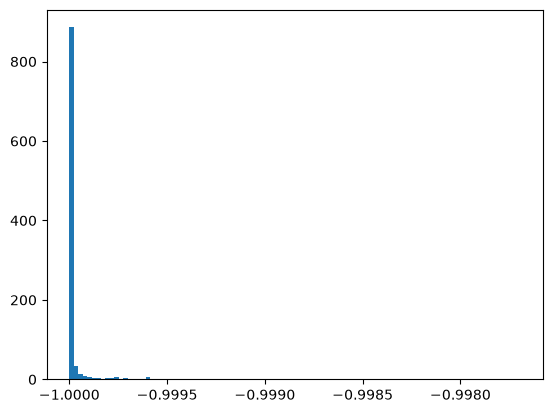

In [46]:
plt.hist(right_phases, bins=100)

#### Cocyle information

In [47]:
cocycle_equation_array = np.array([d['cocycle_equation_output'] for d in results])
print(np.linalg.norm(cocycle_equation_array-1))
print(np.max(np.abs(cocycle_equation_array-1)))

0.039310883151499026
0.007815346029563464


In [48]:
cocycle_equation_array.shape

(1000, 2, 4, 4, 4)

In [49]:
cocycle_equation_array_diffs = np.max(np.abs(cocycle_equation_array.reshape((1000, -1))-1), axis=1)

In [50]:
pd.Series(cocycle_equation_array_diffs).describe()

count    1.000000e+03
mean     1.146502e-04
std      4.157788e-04
min      6.445071e-09
25%      7.664620e-07
50%      5.263926e-06
75%      3.583152e-05
max      7.815346e-03
dtype: float64

(array([831.,  39.,  24.,  18.,  15.,   9.,   5.,   5.,   6.,   6.,   6.,
          4.,   2.,   4.,   2.,   1.,   2.,   1.,   4.,   3.,   2.,   0.,
          0.,   0.,   0.,   1.,   0.,   1.,   0.,   2.,   3.,   0.,   1.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   1.,   0.,
          1.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          1.]),
 array([6.44507142e-09, 7.81598409e-05, 1.56313237e-04, 2.34466633e-04,
        3.12620028e-04, 3.90773424e-04, 4.68926820e-04, 5.47080216e-04,
        6.25233612e-04, 7.03387008e-04, 7.81540404e-04, 8.59693799e-04,
        9.37847195e-04, 1.01600059e-03, 1.09415399e-03, 1.17230738e-03,
        1.25046078e-03, 1.3286

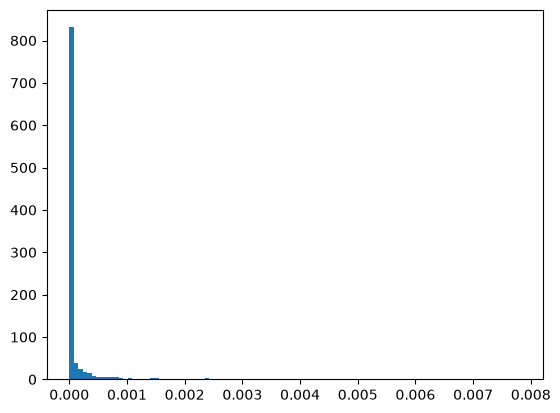

In [51]:
plt.hist(cocycle_equation_array_diffs, bins=100)

Better!

In [52]:
bosonic_cocycle_equation_array = np.array([d['bosonic_cocycle_equation_output'] for d in results])

In [53]:
bosonic_cocycle_equation_array.shape

(1000, 2, 2, 2, 2)

In [54]:
bosonic_cocycle_equation_array_copy = bosonic_cocycle_equation_array.copy()
bosonic_cocycle_equation_array_copy[..., -1, -1, -1] = 1
bosonic_cocycle_equation_array_diffs_1 = np.max(np.abs(bosonic_cocycle_equation_array_copy.reshape((1000, -1))-1), axis=1)

In [55]:
bosonic_cocycle_equation_array_diffs_2 = np.max(np.abs(
    bosonic_cocycle_equation_array[..., -1, -1, -1] + 1
), axis=1)

In [56]:
bosonic_cocycle_equation_array_diffs = np.stack([
    bosonic_cocycle_equation_array_diffs_1,
    bosonic_cocycle_equation_array_diffs_2
], axis=1)

In [57]:
bosonic_cocycle_equation_array_diffs = np.max(bosonic_cocycle_equation_array_diffs, axis=1)

In [58]:
pd.Series(bosonic_cocycle_equation_array_diffs).describe()

count    1.000000e+03
mean     2.508951e-05
std      1.255073e-04
min      4.806623e-10
25%      1.178416e-07
50%      7.327490e-07
75%      5.888410e-06
max      3.008764e-03
dtype: float64

(array([883.,  40.,  19.,   8.,  11.,   4.,   7.,   3.,   2.,   4.,   2.,
          0.,   1.,   1.,   1.,   2.,   2.,   2.,   1.,   1.,   0.,   1.,
          1.,   1.,   0.,   0.,   0.,   0.,   0.,   1.,   1.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          1.]),
 array([4.80662308e-10, 3.00881113e-05, 6.01757420e-05, 9.02633726e-05,
        1.20351003e-04, 1.50438634e-04, 1.80526265e-04, 2.10613895e-04,
        2.40701526e-04, 2.70789157e-04, 3.00876787e-04, 3.30964418e-04,
        3.61052049e-04, 3.91139679e-04, 4.21227310e-04, 4.51314941e-04,
        4.81402571e-04, 5.1149

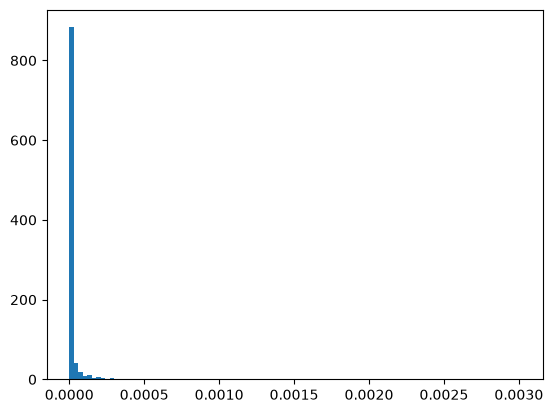

In [59]:
plt.hist(bosonic_cocycle_equation_array_diffs, bins=100)

In [60]:
np.round(
    np.array([d['cocycles'][:, 0, 0] for d in results])
, 3)

array([[ 0.+1.j, -0.-1.j],
       [-0.+1.j,  0.-1.j],
       [ 0.+1.j, -0.-1.j],
       ...,
       [ 0.+1.j,  0.-1.j],
       [-0.-1.j, -0.+1.j],
       [-0.-1.j, -0.+1.j]], shape=(1000, 2))

In [61]:
np.round(
    np.array([d['fermion_decoration_from_cocycle'] for d in results])
, 3)

array([[-1.+0.j, -1.+0.j],
       [-1.-0.j, -1.+0.j],
       [-1.+0.j, -1.+0.j],
       ...,
       [-1.+0.j, -1.+0.j],
       [-1.-0.j, -1.-0.j],
       [-1.+0.j, -1.-0.j]], shape=(1000, 2))

In [62]:
X = np.stack([left_phases, right_phases], axis=1)

In [63]:
Y = np.array([d['fermion_decoration_from_cocycle'] for d in results])

In [64]:
np.linalg.norm(X-Y)

np.float64(0.006050923385218825)

In [65]:
X = np.array([d['cocycles'][:,0,1] for d in results])

In [66]:
results[0]['cocycles'].shape

(2, 3, 3)

In [67]:
X

array([[-0.99999998+4.35466363e-09j, -0.99999997+4.88839455e-08j],
       [-0.99999975-1.53133878e-07j, -1.00000004+9.42817823e-09j],
       [-1.        +1.82671865e-08j, -0.99999998+2.32664295e-08j],
       ...,
       [-1.0000001 +1.55983912e-08j, -1.0000035 +4.39959783e-06j],
       [-1.00000001-1.71398436e-08j, -0.99999988-1.00940647e-06j],
       [-1.        +3.89400415e-11j, -1.00000052-3.97892610e-07j]],
      shape=(1000, 2))

# Product state - results

In [70]:
with open(r"results/z_4_tf_product_results.pkl", "rb") as file:
    results = pickle.load(file)

### Analyze results

#### Projector scores

In [71]:
np.round(np.array([
    d['left_proj_vec_results'][0][-1]
    for d in results
]), 3)

array([ 0., -0.,  0., -0., -0.,  0., -0.,  0., -0.,  0., -0.,  0.,  0.,
       -0., -0.,  0.,  0.,  0., -0.,  0.,  0., -0., -0.,  0.,  0.,  0.,
        0., -0.,  0.,  0., -0.,  0.,  0.,  0.,  0., -0.,  0.,  0., -0.,
       -0.,  0., -0.,  0., -0.,  0.,  0., -0.,  0., -0., -0.,  0., -0.,
       -0.,  0.,  0., -0.,  0.,  0.,  0.,  0.,  0., -0., -0.,  0., -0.,
        0.,  0.,  0.,  0.,  0., -0., -0., -0.,  0.,  0.,  0.,  0., -0.,
        0.,  0.,  0., -0.,  0., -0.,  0.,  0.,  0., -0.,  0., -0.,  0.,
        0.,  0.,  0., -0., -0., -0., -0., -0.,  0., -0.,  0.,  0., -0.,
        0., -0., -0., -0., -0.,  0.,  0., -0.,  0.,  0.,  0.,  0., -0.,
       -0.,  0., -0.,  0., -0., -0.,  0., -0., -0., -0., -0., -0., -0.,
        0.,  0.,  0., -0., -0.,  0., -0., -0.,  0.,  0., -0., -0.,  0.,
       -0., -0., -0.,  0., -0., -0.,  0., -0., -0., -0., -0., -0.,  0.,
       -0., -0.,  0., -0.,  0.,  0.,  0.,  0., -0.,  0., -0., -0., -0.,
       -0., -0., -0.,  0.,  0.,  0., -0., -0., -0.,  0., -0.,  0

In [72]:
np.round(np.array([
    d['right_proj_vec_results'][0][-1]
    for d in results
]), 3)

array([-0.,  0., -0.,  0., -0.,  0.,  0.,  0., -0., -0.,  0., -0.,  0.,
       -0., -0.,  0., -0.,  0., -0., -0., -0., -0., -0.,  0.,  0., -0.,
        0.,  0.,  0., -0., -0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
        0.,  0., -0., -0., -0., -0., -0., -0.,  0., -0.,  0., -0.,  0.,
        0.,  0.,  0.,  0., -0., -0.,  0.,  0.,  0.,  0.,  0., -0., -0.,
        0.,  0.,  0.,  0., -0., -0.,  0., -0.,  0.,  0., -0., -0.,  0.,
       -0., -0., -0., -0., -0., -0.,  0.,  0.,  0.,  0., -0.,  0., -0.,
       -0.,  0.,  0., -0., -0., -0., -0., -0., -0.,  0., -0., -0., -0.,
       -0., -0.,  0., -0.,  0.,  0.,  0.,  0., -0., -0.,  0.,  0.,  0.,
        0., -0.,  0., -0., -0., -0., -0.,  0.,  0., -0., -0., -0.,  0.,
       -0., -0.,  0.,  0.,  0.,  0., -0., -0., -0.,  0., -0., -0.,  0.,
       -0.,  0.,  0., -0., -0.,  0., -0., -0., -0.,  0.,  0., -0.,  0.,
       -0.,  0., -0.,  0., -0.,  0., -0., -0.,  0.,  0., -0., -0., -0.,
        0.,  0., -0.,  0., -0.,  0.,  0.,  0.,  0.,  0.,  0., -0

There is an error interpreting these, according to ChatGPT.

In [73]:
def get_schmidt_vals_ratio(schmidt_vals):
    if len(schmidt_vals.data) > 1:
        return schmidt_vals.data[1]/schmidt_vals.data[0]
    else:
        return 0

In [74]:
np.round(np.array([
    get_schmidt_vals_ratio(d['left_proj_vec_results'][1])
    for d in results
]), 3)

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [75]:
np.round(np.array([
    get_schmidt_vals_ratio(d['right_proj_vec_results'][1])
    for d in results
]), 3)

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

#### Purities

In [76]:
np.round(np.array(
    [d['cut_rho_purity'] for d in results]
), 3)

array([1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j,
       1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j,
       1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j,
       1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j,
       1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j,
       1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j,
       1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j,
       1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j,
       1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j,
       1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j,
       1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j,
       1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j,
       1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j,
       1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j,
      

In [77]:
np.round(np.array(
    [d['sub_cut_rho_trace'] for d in results]
), 3)

array([1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j,
       1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j,
       1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j,
       1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j,
       1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j,
       1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j,
       1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j,
       1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j,
       1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j,
       1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j,
       1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j,
       1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j,
       1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j,
       1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j,
      

In [78]:
np.round(np.array(
    [d['sub_cut_rho_purity'] for d in results]
), 3)

array([1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j,
       1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j,
       1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j,
       1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j,
       1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j,
       1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j,
       1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j,
       1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j,
       1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j,
       1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j,
       1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j,
       1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j,
       1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j,
       1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j,
      

Purities are the same, which one could likely prove.

In [79]:
np.round(np.array(
    [d['sub_cut_rho_purity'] for d in results]
), 3)

array([1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j,
       1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j,
       1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j,
       1.-0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j,
       1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j,
       1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j,
       1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j,
       1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j,
       1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j,
       1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.-0.j,
       1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.+0.j,
       1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.+0.j, 1.-0.j,
       1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j,
       1.+0.j, 1.-0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j, 1.-0.j, 1.+0.j,
      

In [80]:
X = np.array(
    [d['sub_cut_rho_purity'] for d in results]
)

In [81]:
np.max(np.abs(np.imag(X)))

np.float64(1.7652546091539964e-14)

In [82]:
X = np.real(X)

In [83]:
pd.Series(X).describe()

count    1.000000e+03
mean     1.000000e+00
std      1.575431e-15
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
dtype: float64

(array([  1.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   1.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          1.,   2.,   0.,   0.,   0.,   2.,   0.,   0.,   2.,   3.,   4.,
         11.,  10.,  24.,  25.,  40.,  51.,  47.,  86.,  56.,  86.,  78.,
         31., 133.,  68.,  26.,  63.,  18.,  56.,  25.,   9.,  10.,  16.,
          1.,   3.,   3.,   1.,   2.,   0.,   0.,   1.,   0.,   0.,   0.,
          0.,   0.,   2.,   1.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          1.]),
 array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1.

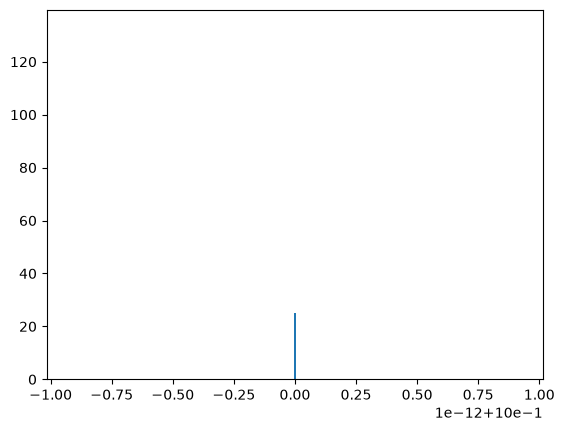

In [84]:
plt.hist(X, bins=100)

#### Cut state results

In [85]:
np.array(
    [d['cut_state_fermion_parity'] for d in results]
)

array([1.+1.04349962e-19j, 1.+2.80434316e-19j, 1.-2.03008220e-19j,
       1.+1.58246329e-18j, 1.+2.95486287e-18j, 1.-1.05640487e-19j,
       1.+1.13052972e-18j, 1.+6.34820854e-19j, 1.+6.49109994e-19j,
       1.+6.80525794e-19j, 1.+2.18251995e-18j, 1.-1.39175085e-18j,
       1.-1.74397104e-19j, 1.+3.85399727e-19j, 1.+1.45527213e-20j,
       1.-8.84629534e-20j, 1.+8.75896245e-19j, 1.-4.56740873e-19j,
       1.+4.35122266e-19j, 1.+1.39691775e-18j, 1.+5.03112903e-19j,
       1.+1.66810371e-19j, 1.-2.76879007e-19j, 1.-1.07572684e-19j,
       1.+2.95012526e-20j, 1.-1.77078237e-18j, 1.+5.36699968e-19j,
       1.+1.80583541e-19j, 1.+1.11726263e-18j, 1.+3.09244949e-18j,
       1.-1.00564764e-18j, 1.+1.47787875e-18j, 1.-8.09129799e-19j,
       1.-3.62825331e-19j, 1.-1.19422456e-18j, 1.-6.17392899e-20j,
       1.-7.28358431e-20j, 1.-6.66841922e-19j, 1.-2.58740213e-18j,
       1.+1.55514426e-18j, 1.+1.78865358e-18j, 1.-1.72140954e-18j,
       1.-6.45190348e-19j, 1.+3.28418520e-19j, 1.-1.52878123e-

In [86]:
np.round(np.array(
    [d['cut_overlap'] for d in results]
), 3)

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1., 1., 1.

#### Defect op scores overlaps

In [87]:
np.round(np.array([
    [d['defect_ops_scores'][i][-1] for d in results]
    for i in range(3)
]), 5)

array([[1., 1., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 1., 1., 1.],
       [1., 1., 1., ..., 1., 1., 1.]], shape=(3, 1000))

In [88]:
X = np.array([
    [d['defect_ops_scores'][i][-1] for d in results]
    for i in range(3)
])

In [89]:
pd.DataFrame(X.T).describe()

,0,1,2
count,1.000000e+03,1.000000e+03,1.000000e+03
mean,1.000000e+00,1.000000e+00,1.000000e+00
std,3.705908e-16,3.689725e-16,3.611995e-16
min,1.000000e+00,1.000000e+00,1.000000e+00
25%,1.000000e+00,1.000000e+00,1.000000e+00
50%,1.000000e+00,1.000000e+00,1.000000e+00
75%,1.000000e+00,1.000000e+00,1.000000e+00
max,1.000000e+00,1.000000e+00,1.000000e+00


#### Phases

In [90]:
left_phases = np.array([
    d['left_defect_op_invariant'] for d in results
])

In [91]:
left_phases.shape

(1000,)

In [92]:
np.max(np.abs(np.imag(left_phases)))

np.float64(8.863604974308123e-15)

In [93]:
left_phases = np.real(left_phases)

In [94]:
pd.Series(left_phases).describe()

count    1.000000e+03
mean     1.000000e+00
std      8.562511e-16
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
dtype: float64

In [95]:
right_phases = np.array([
    d['right_defect_op_invariant'] for d in results
])

In [96]:
right_phases.shape

(1000,)

In [97]:
np.max(np.abs(np.imag(right_phases)))

np.float64(8.748916991687195e-15)

In [98]:
right_phases = np.real(right_phases)

In [99]:
pd.Series(right_phases).describe()

count    1.000000e+03
mean     1.000000e+00
std      8.772690e-16
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
dtype: float64

In [100]:
#plt.hist(right_phases, bins=100)

#### Cocyle information

In [101]:
cocycle_equation_array = np.array([d['cocycle_equation_output'] for d in results])
print(np.linalg.norm(cocycle_equation_array-1))
print(np.max(np.abs(cocycle_equation_array-1)))

2.6641646968072417e-13
2.789896689132429e-14


In [102]:
cocycle_equation_array.shape

(1000, 2, 4, 4, 4)

In [103]:
cocycle_equation_array_diffs = np.max(np.abs(cocycle_equation_array.reshape((1000, -1))-1), axis=1)

In [104]:
pd.Series(cocycle_equation_array_diffs).describe()

count    1.000000e+03
mean     1.524466e-15
std      1.481805e-15
min      5.192389e-16
25%      1.018330e-15
50%      1.333197e-15
75%      1.665464e-15
max      2.789897e-14
dtype: float64

(array([ 76., 184., 278., 201., 104.,  63.,  33.,  25.,  12.,   2.,   3.,
          3.,   1.,   0.,   1.,   0.,   1.,   0.,   2.,   0.,   0.,   1.,
          1.,   1.,   1.,   0.,   0.,   0.,   1.,   0.,   1.,   0.,   1.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   1.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   1.,   0.,   0.,   0.,   0.,   1.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          1.]),
 array([5.19238905e-16, 7.93036185e-16, 1.06683347e-15, 1.34063075e-15,
        1.61442802e-15, 1.88822530e-15, 2.16202258e-15, 2.43581986e-15,
        2.70961714e-15, 2.98341442e-15, 3.25721170e-15, 3.53100898e-15,
        3.80480626e-15, 4.07860354e-15, 4.35240082e-15, 4.62619810e-15,
        4.89999538e-15, 5.1737

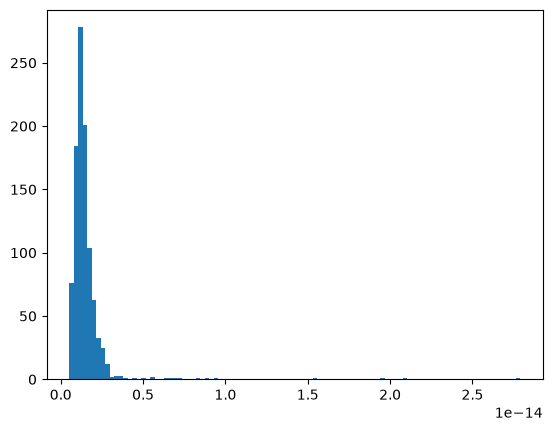

In [105]:
plt.hist(cocycle_equation_array_diffs, bins=100)

Better!

In [106]:
bosonic_cocycle_equation_array = np.array([d['bosonic_cocycle_equation_output'] for d in results])

In [107]:
bosonic_cocycle_equation_array.shape

(1000, 2, 2, 2, 2)

In [108]:
bosonic_cocycle_equation_array_copy = bosonic_cocycle_equation_array.copy()
bosonic_cocycle_equation_array_copy[..., -1, -1, -1] = 1
bosonic_cocycle_equation_array_diffs_1 = np.max(np.abs(bosonic_cocycle_equation_array_copy.reshape((1000, -1))-1), axis=1)

In [109]:
bosonic_cocycle_equation_array_diffs_2 = np.max(np.abs(
    bosonic_cocycle_equation_array[..., -1, -1, -1] + 1
), axis=1)

In [110]:
bosonic_cocycle_equation_array_diffs = np.stack([
    bosonic_cocycle_equation_array_diffs_1,
    bosonic_cocycle_equation_array_diffs_2
], axis=1)

In [111]:
bosonic_cocycle_equation_array_diffs = np.max(bosonic_cocycle_equation_array_diffs, axis=1)

In [112]:
pd.Series(bosonic_cocycle_equation_array_diffs).describe()

count    1000.0
mean        2.0
std         0.0
min         2.0
25%         2.0
50%         2.0
75%         2.0
max         2.0
dtype: float64

(array([   0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0., 1000.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.]),
 array([1.5 , 1.51, 1.52, 1.53, 1.54, 1.55, 1.56, 1.57, 1.58, 1.59, 1.6 ,
        1.61, 1.62, 1.63, 1.64, 1.65, 1.66, 1.67, 1.68, 1.69, 1.7 , 1.71,
        1.72, 1.73, 1.74, 1.75, 1.76, 1.77, 1.78, 1.79

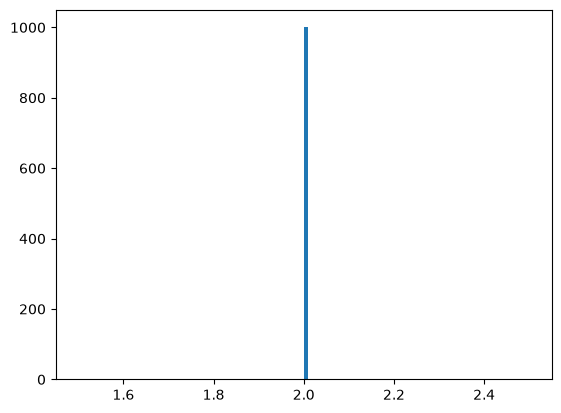

In [113]:
plt.hist(bosonic_cocycle_equation_array_diffs, bins=100)

In [114]:
np.round(
    np.array([d['cocycles'][:, 0, 0] for d in results])
, 3)

array([[ 1.+0.j,  1.+0.j],
       [ 1.-0.j,  1.-0.j],
       [ 1.+0.j,  1.+0.j],
       ...,
       [-1.+0.j, -1.+0.j],
       [ 1.+0.j,  1.+0.j],
       [-1.+0.j, -1.+0.j]], shape=(1000, 2))

In [115]:
np.round(
    np.array([d['fermion_decoration_from_cocycle'] for d in results])
, 3)

array([[1.+0.j, 1.+0.j],
       [1.-0.j, 1.+0.j],
       [1.+0.j, 1.+0.j],
       ...,
       [1.-0.j, 1.-0.j],
       [1.-0.j, 1.+0.j],
       [1.-0.j, 1.-0.j]], shape=(1000, 2))

In [116]:
X = np.array([d['cocycles'][:,1,2] for d in results])

In [117]:
X

array([[1.+2.60323353e-17j, 1.-1.62492277e-17j],
       [1.+2.47481382e-16j, 1.-1.94570290e-16j],
       [1.+4.70824430e-16j, 1.+2.78096540e-16j],
       ...,
       [1.-2.72465224e-16j, 1.-1.46150374e-16j],
       [1.-3.63278402e-17j, 1.-2.66522952e-16j],
       [1.+3.99619837e-16j, 1.+8.64498033e-17j]], shape=(1000, 2))